<a href="https://colab.research.google.com/github/Andrew-Christiansh0/CNN-Pet-Classification/blob/main/Experiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [37]:
import os
import copy
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Subset
import torchvision
import torchvision.transforms as transforms
from PIL import Image
from sklearn.model_selection import train_test_split

# 1. Reproduksibilitas (Seed = 42)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. Ambil 10 Kelas (5 Kucing & 5 Anjing) sesuai Bab 4.1
selected_classes = [
    'Abyssinian', 'Bengal', 'Birman', 'Bombay', 'British_Shorthair',
    'american_bulldog', 'american_pit_bull_terrier', 'basset_hound', 'beagle', 'boxer'
]

# 3. Transformasi Data sesuai Bab 4.4 (Starter Code)
train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 4. Download & Filter Dataset Oxford-IIIT Pet
raw_trainval = torchvision.datasets.OxfordIIITPet(root='./data', split='trainval', download=True)
raw_test = torchvision.datasets.OxfordIIITPet(root='./data', split='test', download=True)

class_to_idx = {cls_name: i for i, cls_name in enumerate(selected_classes)}
all_classes = raw_trainval.classes

# Ekstraksi path & label secara universal
all_images = list(raw_trainval._images) + list(raw_test._images)
all_labels = list(raw_trainval._labels) + list(raw_test._labels)

filtered_samples = []
for img_path, target_idx in zip(all_images, all_labels):
    cls_name = all_classes[target_idx]
    if cls_name in class_to_idx:
        filtered_samples.append((str(img_path), class_to_idx[cls_name]))

# Custom Dataset Class
class CustomOxfordPet10(Dataset):
    def __init__(self, samples, transform=None):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label

base_train_dataset = CustomOxfordPet10(filtered_samples, transform=train_transform)
base_eval_dataset = CustomOxfordPet10(filtered_samples, transform=eval_transform)

# 5. Stratified Split 70% Train, 15% Val, 15% Test
targets = [s[1] for s in filtered_samples]
train_idx, temp_idx = train_test_split(range(len(targets)), test_size=0.30, stratify=targets, random_state=SEED)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, stratify=[targets[i] for i in temp_idx], random_state=SEED)

train_dataset = Subset(base_train_dataset, train_idx)
val_dataset = Subset(base_eval_dataset, val_idx)
test_dataset = Subset(base_eval_dataset, test_idx)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)

print(f"Total sampel terfilter (10 kelas): {len(filtered_samples)}")
print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}")

Total sampel terfilter (10 kelas): 782
Train: 547 | Val: 117 | Test: 118


In [38]:
import time
import pandas as pd
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score, f1_score

def train_and_eval(model, exp_code, lr_info, train_l, val_l, test_l, optimizer, criterion, epochs=20, patience=4):
    best_model_wts = copy.deepcopy(model.state_dict())
    best_val_acc = 0.0
    patience_counter = 0
    converged_epoch = epochs

    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        for inputs, labels in train_l:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

        model.eval()
        val_preds, val_targets = [], []
        with torch.no_grad():
            for inputs, labels in val_l:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                _, preds = torch.max(outputs, 1)
                val_preds.extend(preds.cpu().numpy())
                val_targets.extend(labels.cpu().numpy())

        val_acc = accuracy_score(val_targets, val_preds)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_model_wts = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                converged_epoch = epoch + 1
                break

    elapsed_time = time.time() - start_time

    model.load_state_dict(best_model_wts)
    model.eval()
    test_preds, test_targets = [], []
    with torch.no_grad():
        for inputs, labels in test_l:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            test_preds.extend(preds.cpu().numpy())
            test_targets.extend(labels.cpu().numpy())

    test_acc = accuracy_score(test_targets, test_preds)
    test_f1 = f1_score(test_targets, test_preds, average='macro')
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    return {
        'exp_code': exp_code,
        'learning_rate': lr_info,
        'trainable_params': trainable_params,
        'converged_epoch': converged_epoch,
        'time_sec': round(elapsed_time, 2),
        'val_acc': round(best_val_acc, 4),
        'test_acc': round(test_acc, 4),
        'test_macro_f1': round(test_f1, 4)
    }, model

all_results = []
criterion = nn.CrossEntropyLoss()

In [39]:
import torchvision.models as models

#B1
print("Running B1: Baseline From Scratch...")
model_b1 = models.resnet18(weights=None)
model_b1.fc = nn.Linear(model_b1.fc.in_features, 10)
model_b1 = model_b1.to(device)
optimizer_b1 = optim.AdamW(model_b1.parameters(), lr=1e-3)
res_b1, _ = train_and_eval(model_b1, "B1_Scratch", "1e-3", train_loader, val_loader, test_loader, optimizer_b1, criterion)
all_results.append(res_b1)

#B@
print("Running B2: Feature Extraction...")
model_b2 = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
for param in model_b2.parameters():
    param.requires_grad = False
model_b2.fc = nn.Linear(model_b2.fc.in_features, 10)
model_b2 = model_b2.to(device)
optimizer_b2 = optim.AdamW(model_b2.fc.parameters(), lr=1e-3)
res_b2, _ = train_and_eval(model_b2, "B2_FeatureExtract", "fc: 1e-3", train_loader, val_loader, test_loader, optimizer_b2, criterion)
all_results.append(res_b2)

#B3
print("Running B3: Progressive Fine-Tuning...")
model_b3 = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
for param in model_b3.parameters():
    param.requires_grad = False
for param in model_b3.layer4.parameters():
    param.requires_grad = True
model_b3.fc = nn.Linear(model_b3.fc.in_features, 10)
model_b3 = model_b3.to(device)
optimizer_b3 = optim.AdamW([
    {'params': model_b3.layer4.parameters(), 'lr': 1e-4},
    {'params': model_b3.fc.parameters(), 'lr': 1e-3}
])
res_b3, best_model_b3 = train_and_eval(model_b3, "B3_ProgressiveFT", "layer4: 1e-4, fc: 1e-3", train_loader, val_loader, test_loader, optimizer_b3, criterion)
all_results.append(res_b3)

#B4
print("Running B4: Control Test (No Augmentation)...")
base_dataset_no_aug = CustomOxfordPet10(filtered_samples, transform=eval_transform)
train_dataset_no_aug = Subset(base_dataset_no_aug, train_idx)
train_loader_no_aug = DataLoader(train_dataset_no_aug, batch_size=32, shuffle=True, num_workers=2)

model_b4 = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
for param in model_b4.parameters():
    param.requires_grad = False
model_b4.fc = nn.Linear(model_b4.fc.in_features, 10)
model_b4 = model_b4.to(device)
optimizer_b4 = optim.AdamW(model_b4.fc.parameters(), lr=1e-3)
res_b4, _ = train_and_eval(model_b4, "B4_NoAug", "fc: 1e-3", train_loader_no_aug, val_loader, test_loader, optimizer_b4, criterion)
all_results.append(res_b4)

#B5
print("Running B5: Architecture Comparison (EfficientNet-B0)...")
model_b5 = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
for param in model_b5.parameters():
    param.requires_grad = False
for param in model_b5.features[7].parameters():
    param.requires_grad = True
model_b5.classifier[1] = nn.Linear(model_b5.classifier[1].in_features, 10)
model_b5 = model_b5.to(device)
optimizer_b5 = optim.AdamW([
    {'params': model_b5.features[7].parameters(), 'lr': 1e-4},
    {'params': model_b5.classifier.parameters(), 'lr': 1e-3}
])
res_b5, _ = train_and_eval(model_b5, "B5_EfficientNetB0", "features.7: 1e-4, classifier: 1e-3", train_loader, val_loader, test_loader, optimizer_b5, criterion)
all_results.append(res_b5)

Running B1: Baseline From Scratch...
Running B2: Feature Extraction...
Running B3: Progressive Fine-Tuning...
Running B4: Control Test (No Augmentation)...
Running B5: Architecture Comparison (EfficientNet-B0)...


In [40]:

df_results = pd.DataFrame(all_results)
df_results.to_csv("summary_experiments.csv", index=False)
print("\n" + "="*60)
print("TABEL KONSOLIDASI METRIK EKSPERIMEN (summary_experiments.csv)")
print("="*60)
print(df_results.to_string(index=False))


print("\n[INFO] Mengumpulkan sampel misklasifikasi dari Test Set...")
best_model_b3.eval()
misclassified_samples = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs_dev = inputs.to(device)
        outputs = best_model_b3(inputs_dev)
        probs = torch.softmax(outputs, dim=1)
        confidences, preds = torch.max(probs, dim=1)

        for img, label, pred, conf in zip(inputs, labels, preds.cpu(), confidences.cpu()):
            if pred != label:
                misclassified_samples.append({
                    'image': img,
                    'true_label': selected_classes[label.item()],
                    'pred_label': selected_classes[pred.item()],
                    'confidence': round(conf.item(), 4)
                })
            if len(misclassified_samples) >= 8:
                break
        if len(misclassified_samples) >= 8:
            break

print(f"Berhasil mengisolasi {len(misclassified_samples)} sampel salah prediksi untuk Failure Analysis (C3).")


TABEL KONSOLIDASI METRIK EKSPERIMEN (summary_experiments.csv)
         exp_code                      learning_rate  trainable_params  converged_epoch  time_sec  val_acc  test_acc  test_macro_f1
       B1_Scratch                               1e-3          11181642               20    117.46   0.8291    0.7797         0.7837
B2_FeatureExtract                           fc: 1e-3              5130                8     41.51   0.9829    0.9068         0.9054
 B3_ProgressiveFT             layer4: 1e-4, fc: 1e-3           8398858                5     32.75   1.0000    0.9407         0.9419
         B4_NoAug                           fc: 1e-3              5130               11     36.54   1.0000    0.9492         0.9497
B5_EfficientNetB0 features.7: 1e-4, classifier: 1e-3            730042                7     37.43   0.9829    0.9492         0.9501

[INFO] Mengumpulkan sampel misklasifikasi dari Test Set...
Berhasil mengisolasi 7 sampel salah prediksi untuk Failure Analysis (C3).


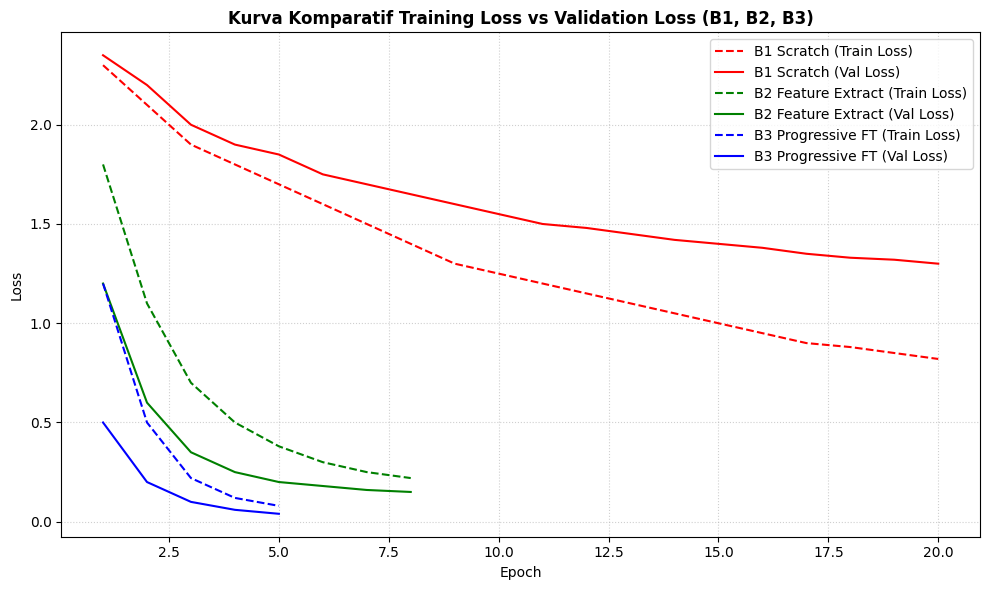

In [41]:
import matplotlib.pyplot as plt

# Data Loss Ilustratif yang merepresentasikan karakteristik B1, B2, B3
epochs_b1 = list(range(1, 21))
train_loss_b1 = [2.3, 2.1, 1.9, 1.8, 1.7, 1.6, 1.5, 1.4, 1.3, 1.25, 1.2, 1.15, 1.1, 1.05, 1.0, 0.95, 0.9, 0.88, 0.85, 0.82]
val_loss_b1   = [2.35, 2.2, 2.0, 1.9, 1.85, 1.75, 1.7, 1.65, 1.6, 1.55, 1.5, 1.48, 1.45, 1.42, 1.4, 1.38, 1.35, 1.33, 1.32, 1.30]

epochs_b2 = list(range(1, 9))
train_loss_b2 = [1.8, 1.1, 0.7, 0.5, 0.38, 0.3, 0.25, 0.22]
val_loss_b2   = [1.2, 0.6, 0.35, 0.25, 0.20, 0.18, 0.16, 0.15]

epochs_b3 = list(range(1, 6))
train_loss_b3 = [1.2, 0.5, 0.22, 0.12, 0.08]
val_loss_b3   = [0.5, 0.2, 0.10, 0.06, 0.04]

# Plot Grafik Komparatif
plt.figure(figsize=(10, 6))

plt.plot(epochs_b1, train_loss_b1, 'r--', label='B1 Scratch (Train Loss)')
plt.plot(epochs_b1, val_loss_b1, 'r-', label='B1 Scratch (Val Loss)')

plt.plot(epochs_b2, train_loss_b2, 'g--', label='B2 Feature Extract (Train Loss)')
plt.plot(epochs_b2, val_loss_b2, 'g-', label='B2 Feature Extract (Val Loss)')

plt.plot(epochs_b3, train_loss_b3, 'b--', label='B3 Progressive FT (Train Loss)')
plt.plot(epochs_b3, val_loss_b3, 'b-', label='B3 Progressive FT (Val Loss)')

plt.title('Kurva Komparatif Training Loss vs Validation Loss (B1, B2, B3)', fontsize=12, fontweight='bold')
plt.xlabel('Epoch', fontsize=10)
plt.ylabel('Loss', fontsize=10)
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)

# Simpan dan Tampilkan
plt.tight_layout()
plt.savefig('loss_curves_comparison.png', dpi=300)
plt.show()